# Foreign holdings and currency: what the tax man takes, and where

Two things change the tax on a US stock or a US-focused fund that a Canadian stock never shows. The first is withholding: the US keeps 15% of a US dividend before you see it, and what happens to that 15% depends on the account (taxable, TFSA, RRSP) and on the wrapper (the US stock itself, a US-listed ETF, or a Canadian-listed ETF that holds US stocks). The second is currency: the CRA taxes your gain in Canadian dollars, so a US stock that rises 10% in US dollars can still be a loss for tax purposes if the US dollar fell 15% against the Canadian dollar, because the cost base (ACB) is fixed in Canadian dollars on the day you buy.

This notebook builds tiny hand-made markets in which each effect appears alone, then points at the bundled S&P 500 sample. It is the deeper companion to `accounts_and_foreign.ipynb` and uses no random simulation, so every number is arithmetic you could check by hand. **Each section has one base case, named in its text and drawn grey and dashed in every chart and as the row marked "Buy and hold" in every table.** In Sections 1 and 2 it is the same holding bought and held in a taxable account. In Section 3 it is the same stock with the exchange rate held at its buy-day value. In Section 4, where an index exists, it is buy and hold of the index in the same account. The notebook runs offline in about 30 seconds and writes no files. Not tax advice.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Rectangle
from IPython.display import display, Markdown

try:
    import screenlab
except ImportError:                       # running from a git checkout without installing the package
    sys.path.insert(0, str(Path.cwd().parent.parent))
    import screenlab
from screenlab import Config, Market, ScreenBuilder
from screenlab.backtest import run
from screenlab.data import add_ratios, security_meta
from screenlab.dataset import Dataset
from screenlab.macro import MacroSeries
from screenlab.taxes import CanadianTax, TaxConfig, FX_WARNING
from screenlab.ops.account_compare import treatment, _ledger_capture
from screenlab.research import tax_plots as tp
from screenlab.research.montecarlo_sp500 import INK, INK2, SURFACE, GRID, _style

%matplotlib inline
plt.rcParams["figure.dpi"] = 80
_style()

MODEL = CanadianTax("AB", other_income=90_000)       # Alberta, $90,000 of other income, the same as the accounts notebook
CAP = 100_000.0                                       # starting money, dollars
ACCOUNTS = ["taxable", "tfsa", "rrsp"]
ACC_NAME = {"taxable": "Taxable", "tfsa": "TFSA", "rrsp": "RRSP"}
ACC_COL = {"taxable": "#0072B2", "tfsa": "#E69F00", "rrsp": "#CC79A7"}     # colour-blind-safe, one hue per account
STATE_COL = {"none": "#E3E2DD", "credited": "#56B4E9", "exempt": "#009E73", "lost": "#D55E00"}
GREY = "#6B6B6B"                                      # the base case is always grey and dashed
BASE_TAXABLE = "Buy and hold the same name in a taxable account (base)"

def say(text):                                        # a paragraph written from the run's own numbers, so it cannot drift from them
    display(Markdown(text))

def usd(v):                                           # dollars, with the dollar sign escaped so markdown does not read it as maths
    return f"\\${v:,.0f}"

def pts(v):                                           # a fraction as points of growth a year
    return f"{100 * v:.2f}"

def make_market(spec, years=1, yld=0.04, growth=0.0, picks=None, prices=None):
    # spec: {name: security_meta fields}. Every name is on offer at the start of each year (sector = its own name);
    # picks (optional) says which name is in play in which year, as {name: [years]}.
    dates = pd.bdate_range("2020-01-01", f"{2019 + years}-12-31")
    names = list(spec)
    if prices is None:
        path = (1 + growth) ** ((dates - dates[0]).days.to_numpy() / 365.25)
        prices = pd.DataFrame({t: path for t in names}, index=dates)
    rows = [dict(date=pd.Timestamp(f"{2020 + y}-01-01"), ticker=t, sector=(t if (picks is None or 2020 + y in picks[t]) else "off"),
                 price=10.0, market_cap=1000.0, dividend=10.0 * yld) for y in range(years) for t in names]
    meta = security_meta(names, pd.DataFrame([dict(ticker=t, **v) for t, v in spec.items()]).set_index("ticker"))
    return Market(Dataset.from_frames(add_ratios(pd.DataFrame(rows)), prices, security_meta=meta))

def run_name(market, name, account, macro=None, rrsp_rate=0.30):
    # Hold only `name` for the whole run in `account`; returns the backtest result with the event ledger attached.
    tc = TaxConfig(model=MODEL, account=account, capital=CAP, rrsp_withdrawal_rate=rrsp_rate, macro=macro, pay_from_portfolio=False)
    screen = ScreenBuilder(f"only_{name}", n=1).where(f"sector == '{name}'").build()
    with _ledger_capture():
        return run(screen, market, Config(rebalance_months=12, cost_bps=0, min_holdings=1, tax=tc), start="2020-01-01")

def withholding_dollars(res, account, rate=0.15):
    # The foreign withholding of a run, by what happened to it, in dollars per year (from the tax stage's own ledger).
    # lost: nothing gives it back; credited: the foreign tax credit returns it (taxable); exempt: never withheld (RRSP, US).
    _, ev = res.tax.attrs["ledger"]
    ev = ev.reindex(columns=["div_fx", "wh_fx", "wh_fund", "wh_lost"]).fillna(0.0)
    y = ev.groupby(ev.index.year).sum() * CAP
    out = pd.DataFrame(index=y.index, dtype=float)
    out["lost"] = y["wh_fund"] + y["wh_lost"] + (y["wh_fx"] if account == "tfsa" else 0.0)
    out["credited"] = y["wh_fx"] if account == "taxable" else 0.0
    out["exempt"] = y["div_fx"] * rate if account == "rrsp" else 0.0
    return out

def cagr(curve):
    return curve.iloc[-1] ** (365.25 / (curve.index[-1] - curve.index[0]).days) - 1

In [2]:
# All the runs of the notebook, once, so the summary can quote every number it uses.
# ---- Section 1: three names, one yield, three accounts, one year
SPEC1 = {"CA": dict(domicile="CA", wrapper="stock", currency="CAD"),
         "US": dict(domicile="US", wrapper="stock", currency="USD"),
         "ETF_CA": dict(domicile="CA", wrapper="etf_ca", underlying_domicile="US", currency="CAD")}
NICE1 = {"CA": "Canadian stock", "US": "US stock (direct)", "ETF_CA": "Canadian-listed ETF\non US stocks"}
m1 = make_market(SPEC1, years=1, yld=0.04)
cells, rows = {}, []
for name in SPEC1:
    for acct in ACCOUNTS:
        r = run_name(m1, name, acct)
        t = r.tax.loc[2020]
        gross = t["dividends_ca"] + t["dividends_foreign"]
        tax_div = t["tax_dividends"] + t["tax_foreign_dividends"]         # tax on the income only (no RRSP withdrawal tax)
        wh = withholding_dollars(r, acct).loc[2020]
        state = "lost" if wh["lost"] > 0 else "credited" if wh["credited"] > 0 else "exempt" if wh["exempt"] > 0 else "none"
        cells[(name, acct)] = (state, wh[state] if state != "none" else 0.0)
        rows.append(dict(name=name, account=acct, gross=gross, tax=tax_div, after_tax=gross - tax_div,
                         lost=wh["lost"], credited=wh["credited"], exempt=wh["exempt"]))
inc = pd.DataFrame(rows)
inc["vs_base"] = [r.after_tax - inc[(inc["name"] == r["name"]) & (inc["account"] == "taxable")]["after_tax"].iloc[0] for _, r in inc.iterrows()]
I1 = inc.set_index(["name", "account"])
rate = TaxConfig(model=MODEL).rate_for("US")

# ---- Section 2: the same US exposure through a US-listed or a Canadian-listed ETF, ten years
SPEC2 = {"US_ETF": dict(domicile="US", wrapper="etf_us", currency="USD"),
         "CA_ETF": dict(domicile="CA", wrapper="etf_ca", underlying_domicile="US", currency="CAD")}
NICE2 = {"US_ETF": "US-listed ETF", "CA_ETF": "Canadian-listed ETF"}
W_COL = {"US_ETF": "#0072B2", "CA_ETF": "#D55E00"}
m2 = make_market(SPEC2, years=10, yld=0.02, growth=0.07)
fx_flat = MacroSeries.from_frame(pd.DataFrame({"fx": 1.35}, index=m2.dataset.prices.index))
R2 = {(n, a): run_name(m2, n, a, macro=fx_flat) for n in SPEC2 for a in ACCOUNTS}
WH2 = {k: withholding_dollars(r, k[1]) for k, r in R2.items()}
T2 = pd.DataFrame([dict(wrapper=n, account=a, pre=cagr(r.curve), post=cagr(r.after_tax_curve), lost=WH2[(n, a)]["lost"].sum(),
                        credited=WH2[(n, a)]["credited"].sum(), exempt=WH2[(n, a)]["exempt"].sum()) for (n, a), r in R2.items()]).set_index(["wrapper", "account"])
T2["vs_base"] = [T2.loc[(n, a), "post"] - T2.loc[(n, "taxable"), "post"] for n, a in T2.index]
gap = {a: T2.loc[("US_ETF", a), "post"] - T2.loc[("CA_ETF", a), "post"] for a in ACCOUNTS}   # cost of the Canadian-listed wrapper, in growth a year

# ---- Section 3: currency and the cost base
SPEC3 = {"US": dict(domicile="US", wrapper="stock", currency="USD"), "CAN": dict(domicile="CA", wrapper="stock", currency="CAD")}
D3 = pd.bdate_range("2020-01-01", "2021-12-31")
FX0 = 1.40

def case(usd_move, fx_move):
    # Price and FX move in a straight line over 2020 and the sale happens on 2021-01-01.
    frac = np.clip((D3 - D3[0]).days.to_numpy() / (pd.Timestamp("2021-01-01") - D3[0]).days, 0, 1)
    usd_px = 1 + usd_move * frac
    fx = pd.Series(FX0 * (1 + fx_move * frac), index=D3)
    mk = make_market(SPEC3, years=2, yld=0.0, picks={"US": [2020], "CAN": [2021]}, prices=pd.DataFrame({"US": usd_px, "CAN": 1.0}, index=D3))
    macro = MacroSeries.from_frame(pd.DataFrame({"fx": fx}))
    tc = lambda m: TaxConfig(model=MODEL, account="taxable", capital=CAP, macro=m, pay_from_portfolio=False)
    sc = ScreenBuilder("pick", n=1).where("sector == 'US' or sector == 'CAN'").build()
    out = {}
    for key, m in (("cad", macro), ("usd", None)):
        out[key] = run(sc, mk, Config(rebalance_months=12, cost_bps=0, min_holdings=1, tax=tc(m)), start="2020-01-01").tax
    return pd.Series(usd_px, index=D3), fx, out

CASES = {"A": (0.10, -0.15), "B": (-0.05, 0.15)}
RES3 = {k: case(*v) for k, v in CASES.items()}
C3 = {}                                                # (case, view) -> realized gain, realized loss, tax; "usd" is the base (currency ignored)
for k in CASES:
    for key in ("usd", "cad"):
        t = RES3[k][2][key].loc[2021]
        C3[(k, key)] = dict(gain=t["realized_gains"], loss=t["realized_losses"], net=t["realized_gains"] + t["realized_losses"], tax=t["tax_capital_gains"])

# ---- Section 4: the bundled S&P 500 sample with an assumed 2% yield
from screenlab import Lab
from screenlab.benchmarks import IndexBenchmark
from screenlab.dataset import BundledSP500Builder
from screenlab.realdata import bundled

ds = BundledSP500Builder().build()
q = ds.prices.resample("QE").last().dropna(how="all")
rows = [dict(date=d, ticker=t, price=p, sector=bundled.SECTORS[t], market_cap=np.nan, dividend=0.02 * p)
        for d, r in q.iterrows() for t, p in r.dropna().items()]
ds2 = Dataset.from_frames(add_ratios(pd.DataFrame(rows)), ds.prices, ds.indices, name="sp500_bundled+2%div",
                          source="skfolio sample + assumed 2% yield", index_kinds={"SP500": "price"}, pit=None,
                          currency="USD", security_meta=ds.security_meta)
sp = Lab.from_dataset(ds2, screens=bundled.price_screens(5), benchmark=IndexBenchmark("SP500", dividend_yield=0.02))
TAX = TaxConfig(model=MODEL, account="taxable", rrsp_withdrawal_rate=0.30)
sp_rep = sp.account_compare(["momentum_12_1"], tax=TAX, rebalance_months=12)
SPT = sp_rep.table.set_index(["kind", "account"])      # kind: portfolio (the momentum screen) or index (the base case)

In [3]:
# The summary. Every number below is read from the runs above.
us, ca, etf = "US", "CA", "ETF_CA"
a_, b_ = "A", "B"
assert T2.xs("CA_ETF", level="wrapper")["lost"].nunique() == 1
say(f'''
## Summary

**What withholding costs.** A 4% dividend on {usd(CAP)} is {usd(I1.loc[(us, "taxable"), "gross"])} a year, and the US keeps {rate:.0%} of a US dividend: {usd(I1.loc[(us, "tfsa"), "lost"])}, or {pts(I1.loc[(us, "tfsa"), "lost"] / CAP)} points of growth in the year. Whether that is a cost depends on the account and the wrapper. Against the base case, the same name bought and held in a taxable account, a US stock held directly lost nothing in the taxable account (the foreign tax credit returned {usd(I1.loc[(us, "taxable"), "credited"])}), {usd(I1.loc[(us, "tfsa"), "lost"])} in a TFSA, and nothing in an RRSP, where the treaty exempts it. A Canadian-listed ETF on US stocks lost {usd(I1.loc[(etf, "taxable"), "lost"])} in all three accounts, because the fund pays the tax inside before the account sees it. Over ten years, at a 2% yield and 7% growth, that wrapper finished {pts(gap["taxable"])} points a year behind the US-listed ETF in a taxable account, {pts(gap["tfsa"])} in a TFSA and {pts(gap["rrsp"])} in an RRSP, having lost {usd(T2.loc[("CA_ETF", "tfsa"), "lost"])} of withholding per {usd(CAP)} in each account, against {usd(T2.loc[("US_ETF", "taxable"), "lost"])} in the taxable account, {usd(T2.loc[("US_ETF", "tfsa"), "lost"])} in the TFSA and {usd(T2.loc[("US_ETF", "rrsp"), "lost"])} in the RRSP for the US-listed one. In the TFSA, where withholding is the only tax, it cost the US-listed ETF {pts(T2.loc[("US_ETF", "tfsa"), "pre"] - T2.loc[("US_ETF", "tfsa"), "post"])} points a year. On the S&P 500 sample with an assumed 2% yield, the withholding lost was {pts(SPT.loc[("portfolio", "tfsa"), "WHLost/yr"])} points a year in the TFSA and {pts(SPT.loc[("portfolio", "taxable"), "WHLost/yr"])} in the taxable account and the RRSP; against buy and hold of the index in the same account, a momentum screen finished {pts(SPT.loc[("portfolio", "taxable"), "AfterTaxExcess/yr"])}, {pts(SPT.loc[("portfolio", "tfsa"), "AfterTaxExcess/yr"])} and {pts(SPT.loc[("portfolio", "rrsp"), "AfterTaxExcess/yr"])} points a year ahead in the taxable account, TFSA and RRSP, an excess that includes the sample's survivorship bias.

**What the currency does.** The CRA taxes the gain in Canadian dollars. When the US price rose 10% and USDCAD fell 15%, the stock gained {usd(C3[(a_, "usd")]["gain"])} in US dollars, which is the base case and would have been taxed {usd(C3[(a_, "usd")]["tax"])}; in Canadian dollars it lost {usd(-C3[(a_, "cad")]["loss"])} ({C3[(a_, "cad")]["loss"] / CAP:.2%}) and paid {usd(C3[(a_, "cad")]["tax"])}. In the reverse case, the US price down 5% and USDCAD up 15%, the base case showed a {usd(-C3[(b_, "usd")]["loss"])} loss and no tax, while the Canadian-dollar result was a {usd(C3[(b_, "cad")]["gain"])} gain ({C3[(b_, "cad")]["gain"] / CAP:+.2%}) taxed {usd(C3[(b_, "cad")]["tax"])}. The currency therefore moved the taxable result by {usd(abs(C3[(a_, "cad")]["net"] - C3[(a_, "usd")]["net"]))} in the first case and {usd(abs(C3[(b_, "cad")]["net"] - C3[(b_, "usd")]["net"]))} in the second, and the tax by {usd(abs(C3[(a_, "cad")]["tax"] - C3[(a_, "usd")]["tax"]))} and {usd(abs(C3[(b_, "cad")]["tax"] - C3[(b_, "usd")]["tax"]))}.
''')


## Summary

**What withholding costs.** A 4% dividend on \$100,000 is \$3,997 a year, and the US keeps 15% of a US dividend: \$600, or 0.60 points of growth in the year. Whether that is a cost depends on the account and the wrapper. Against the base case, the same name bought and held in a taxable account, a US stock held directly lost nothing in the taxable account (the foreign tax credit returned \$600), \$600 in a TFSA, and nothing in an RRSP, where the treaty exempts it. A Canadian-listed ETF on US stocks lost \$600 in all three accounts, because the fund pays the tax inside before the account sees it. Over ten years, at a 2% yield and 7% growth, that wrapper finished 0.17 points a year behind the US-listed ETF in a taxable account, 0.00 in a TFSA and 0.33 in an RRSP, having lost \$4,286 of withholding per \$100,000 in each account, against \$0 in the taxable account, \$4,286 in the TFSA and \$0 in the RRSP for the US-listed one. In the TFSA, where withholding is the only tax, it cost the US-listed ETF 0.24 points a year. On the S&P 500 sample with an assumed 2% yield, the withholding lost was 0.30 points a year in the TFSA and 0.00 in the taxable account and the RRSP; against buy and hold of the index in the same account, a momentum screen finished 8.84, 11.26 and 11.15 points a year ahead in the taxable account, TFSA and RRSP, an excess that includes the sample's survivorship bias.

**What the currency does.** The CRA taxes the gain in Canadian dollars. When the US price rose 10% and USDCAD fell 15%, the stock gained \$10,000 in US dollars, which is the base case and would have been taxed \$1,525; in Canadian dollars it lost \$6,500 (-6.50%) and paid \$0. In the reverse case, the US price down 5% and USDCAD up 15%, the base case showed a \$5,000 loss and no tax, while the Canadian-dollar result was a \$9,250 gain (+9.25%) taxed \$1,411. The currency therefore moved the taxable result by \$16,500 in the first case and \$14,250 in the second, and the tax by \$1,525 and \$1,411.


## How the test markets are built

The helper in the first cell builds a market of a few names on business days from 2020-01-01. Every name has the same yield and the same price growth, so any difference in the results is the tax and nothing else. A name's metadata (`domicile`, `wrapper`, `currency`, `underlying_domicile`) is what the tax stage reads; in your own data it comes from the optional `securities.csv`. Prices are a total-return index: dividends are paid out in the tax ledger and reinvested. Starting money is \$100,000, and taxes are paid from outside the account (`pay_from_portfolio=False`), so each year's dollars are exact.

## 1. Where the 15% goes, by holding and account

The question is what happens to the foreign withholding in each account and what is left in the investor's hands. It comes first because every later section is a case of this rule.

Three names pay the same 4% yield and do not change in price over one year, so each earns the same \$3,997 on \$100,000 before tax (the dividend is \$3,997 and not \$4,000 because the year has 365 of 365.25 days). **CA** is a Canadian eligible-dividend stock, **US** is a US stock held directly, and **ETF_CA** is a Canadian-listed ETF (in Canadian dollars) that holds US stocks. Each was held alone in a taxable account, a TFSA and an RRSP; the RRSP's withdrawal tax is left out here and only the income is compared. **The base case is the same name bought and held in a taxable account**, shown as the dashed frame around the Taxable column in Figure 1 and as the dashed mark across each group in Figure 2.

In Table 1 each row is one name in one account. The first column is the dividend before anything is taken, the second is everything taken on the income (withholding plus Canadian tax), and the third is what is left. The next three columns split the foreign withholding into the part that is gone for good (lost), the part the taxable account gets back through the foreign tax credit (credited back) and the part the RRSP never pays (exempt, by treaty). The last column is what is left, minus what the same name left in the taxable account.

In [4]:
def classify(text):
    return "lost" if "LOST" in text else "credited" if "creditable" in text else "exempt" if "EXEMPT" in text else "none"

KIND = {"CA": ("domestic", "CA"), "US": ("direct", "US"), "ETF_CA": ("fund", "US")}
doc = {n: {a: classify(treatment(*KIND[n], 0.0 if KIND[n][0] == "domestic" else rate)[a]) for a in ACCOUNTS} for n in SPEC1}
agree = all(doc[n][a] == cells[(n, a)][0] for n in SPEC1 for a in ACCOUNTS)
print("the ledger of the runs agrees with the documented matrix (docs/TAXES.md):", agree)
assert agree

t1 = inc.copy()
t1["holding"] = t1["name"].map(NICE1).str.replace("\n", " ")
t1["account"] = np.where(t1["account"] == "taxable", "Taxable (buy and hold, base)", t1["account"].map(ACC_NAME))
t1 = t1.set_index(["holding", "account"])[["gross", "tax", "after_tax", "lost", "credited", "exempt", "vs_base"]]
t1.columns = ["Dividend before tax", "Tax taken", "Left after tax", "Withholding lost", "Withholding credited back", "Withholding exempt", "Left after tax minus base"]
print("Table 1. Dollars on a $100,000 holding with a 4% yield, over one year")
t1.style.format("{:,.0f}")

the ledger of the runs agrees with the documented matrix (docs/TAXES.md): True
Table 1. Dollars on a $100,000 holding with a 4% yield, over one year


Figure 1 shows the rule and Figure 2 its consequence. In the left chart each cell says what happened to the withheld money and is coloured the same way: orange where it is lost, light blue where the foreign tax credit gives it back, green where it is never taken, grey where no foreign tax is at stake. In the right chart each group is one name, the bars are the three accounts, and the grey dashed mark across the group is the base case, what the same name left in the taxable account.

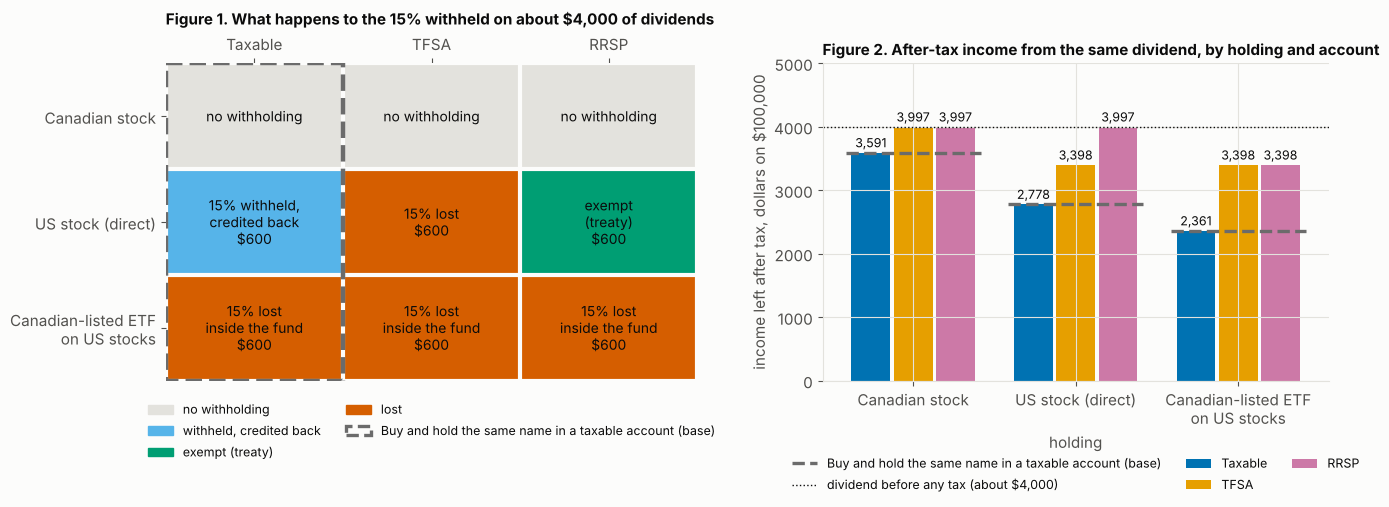

In [5]:
def draw_matrix(ax):
    order = ["none", "credited", "exempt", "lost"]
    z = np.array([[order.index(cells[(n, a)][0]) for a in ACCOUNTS] for n in SPEC1])
    ax.imshow(z, cmap=ListedColormap([STATE_COL[s] for s in order]), vmin=-0.5, vmax=3.5, aspect="auto")
    for i, n in enumerate(SPEC1):
        for j, a in enumerate(ACCOUNTS):
            s, d = cells[(n, a)]
            txt = {"none": "no withholding", "credited": f"{rate:.0%} withheld,\ncredited back", "exempt": "exempt\n(treaty)",
                   "lost": (f"{rate:.0%} lost\ninside the fund" if n == "ETF_CA" else f"{rate:.0%} lost")}[s]
            if s != "none":
                txt += f"\n${d:,.0f}"
            ax.text(j, i, txt, ha="center", va="center", fontsize=10, color=INK)
    ax.set_xticks(range(3), [ACC_NAME[a] for a in ACCOUNTS]); ax.set_yticks(range(3), [NICE1[n] for n in SPEC1])
    ax.xaxis.tick_top(); ax.grid(False)
    for sp_ in ax.spines.values(): sp_.set_visible(False)
    ax.set_title("Figure 1. What happens to the 15% withheld on about $4,000 of dividends", pad=28, loc="left", fontsize=11, fontweight="bold")
    ax.set_xticks(np.arange(-.5, 3), minor=True); ax.set_yticks(np.arange(-.5, 3), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=3); ax.tick_params(which="minor", length=0, top=False, left=False)
    ax.add_patch(Rectangle((-0.5, -0.5), 1, 3, fill=False, ec=GREY, lw=3.2, ls="--", zorder=5))      # the base case: the taxable column
    ax.legend(handles=[Patch(color=STATE_COL["none"], label="no withholding"), Patch(color=STATE_COL["credited"], label="withheld, credited back"),
                       Patch(color=STATE_COL["exempt"], label="exempt (treaty)"), Patch(color=STATE_COL["lost"], label="lost"),
                       Patch(fill=False, ec=GREY, ls="--", lw=2.4, label=BASE_TAXABLE)],
              loc="upper center", bbox_to_anchor=(0.5, -0.03), ncol=2, fontsize=9, frameon=False)

def draw_income(ax):
    x = np.arange(len(SPEC1)); w = 0.26
    for k, a in enumerate(ACCOUNTS):
        v = [I1.loc[(n, a), "after_tax"] for n in SPEC1]
        bars = ax.bar(x + (k - 1) * w, v, w * 0.92, color=ACC_COL[a], label=ACC_NAME[a])
        for b, y in zip(bars, v):
            ax.text(b.get_x() + b.get_width() / 2, y + 40, f"{y:,.0f}", ha="center", va="bottom", fontsize=9, color=INK)
    for i, n in enumerate(SPEC1):
        base = I1.loc[(n, "taxable"), "after_tax"]
        ax.plot([x[i] - 1.6 * w, x[i] + 1.6 * w], [base, base], color=GREY, ls="--", lw=2.4, zorder=4, label=BASE_TAXABLE if i == 0 else None)
    ax.axhline(I1["gross"].iloc[0], color=INK, lw=1, ls=":", label="dividend before any tax (about $4,000)")
    ax.set_xticks(x, [NICE1[n] for n in SPEC1]); ax.set_ylabel("income left after tax, dollars on $100,000"); ax.set_xlabel("holding")
    ax.set_title("Figure 2. After-tax income from the same dividend, by holding and account", loc="left", fontsize=11, fontweight="bold")
    ax.set_ylim(0, 5000)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncols=3, fontsize=9, frameon=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw=dict(width_ratios=[1.05, 1]))
draw_matrix(axes[0]); draw_income(axes[1]); fig.tight_layout(); display(fig); plt.close(fig)

In [6]:
usd_t, usd_f, usd_r = I1.loc[(us, "taxable")], I1.loc[(us, "tfsa")], I1.loc[(us, "rrsp")]
say(f'''
### What the evidence says

The ledger of the runs matched the documented matrix in all nine cells, and the rule it showed was that the same {rate:.0%} was lost, credited or exempt depending on the account and the wrapper. Measured against the base case, the same name in a taxable account, the Canadian stock lost nothing to withholding anywhere and left {usd(I1.loc[(ca, "tfsa"), "after_tax"])} in a TFSA or RRSP against {usd(I1.loc[(ca, "taxable"), "after_tax"])} in the taxable account. The US stock left {usd(usd_t["after_tax"])} in the taxable account, where its {usd(usd_t["credited"])} of withholding was credited against Canadian tax, {usd(usd_f["after_tax"])} in the TFSA, which looks tax free but lost {usd(usd_f["lost"])} ({pts(usd_f["lost"] / CAP)} points of the year's growth) and got none of it back, and {usd(usd_r["after_tax"])} in the RRSP, where nothing is withheld; the RRSP was the best home for the US stock, by {usd(usd_r["vs_base"])} over the base case. The Canadian-listed ETF on US stocks lost {usd(I1.loc[(etf, "taxable"), "lost"])} in every account, the RRSP included, and so left {usd(I1.loc[(etf, "tfsa"), "after_tax"])} even in the TFSA and RRSP. It was the one holding for which no account helped. In the taxable account the Canadian stock left {usd(I1.loc[(ca, "taxable"), "after_tax"] - usd_t["after_tax"])} more than the US stock, because a US dividend is taxed as ordinary income and gets no dividend tax credit.
''')
assert (I1.loc[(etf, slice(None)), "lost"] > 0).all() and I1.loc[(ca, slice(None)), "lost"].sum() == 0


### What the evidence says

The ledger of the runs matched the documented matrix in all nine cells, and the rule it showed was that the same 15% was lost, credited or exempt depending on the account and the wrapper. Measured against the base case, the same name in a taxable account, the Canadian stock lost nothing to withholding anywhere and left \$3,997 in a TFSA or RRSP against \$3,591 in the taxable account. The US stock left \$2,778 in the taxable account, where its \$600 of withholding was credited against Canadian tax, \$3,398 in the TFSA, which looks tax free but lost \$600 (0.60 points of the year's growth) and got none of it back, and \$3,997 in the RRSP, where nothing is withheld; the RRSP was the best home for the US stock, by \$1,219 over the base case. The Canadian-listed ETF on US stocks lost \$600 in every account, the RRSP included, and so left \$3,398 even in the TFSA and RRSP. It was the one holding for which no account helped. In the taxable account the Canadian stock left \$813 more than the US stock, because a US dividend is taxed as ordinary income and gets no dividend tax credit.


## 2. The wrapper: the same US exposure two ways

Section 1 found that the Canadian-listed ETF on US stocks lost the 15% in every account. The question now is what that costs in growth a year over a long holding, against the same US exposure through a US-listed ETF. Two ETFs hold the same US stocks with the same pre-tax return (7% a year growth, 2% yield, ten years). **US_ETF** is listed in the US, in US dollars (`wrapper="etf_us"`, held directly, so the withholding happens at source). **CA_ETF** is listed in Canada, in Canadian dollars (`wrapper="etf_ca"`, `underlying_domicile="US"`, so the withholding happens inside the fund). A flat USDCAD of 1.35 was loaded so that the currency moves nothing and only the wrapper differs.

**The base case is each ETF bought and held in a taxable account.** In Figure 3 it is the grey dashed mark across each bar, set at the level of the same ETF in the taxable account, and in Figure 4 it is the grey dashed line showing the withholding that the same ETF loses there. Table 2 marks the taxable row of each ETF as the base. The RRSP rows include the assumed 30% withdrawal tax on the whole balance, so their difference from the base is mostly that tax and not a withholding effect; the wrappers should be compared inside one account.

In [7]:
t2 = T2.reset_index()
t2["wrapper"] = t2["wrapper"].map(NICE2)
t2["account"] = np.where(t2["account"] == "taxable", "Taxable (buy and hold, base)", t2["account"].map(ACC_NAME))
t2 = t2.set_index(["wrapper", "account"])
t2.columns = ["Growth a year before tax", "Growth a year after tax", "Withholding lost over 10 years ($)", "Credited back ($)", "Exempt ($)", "After-tax growth minus base"]
t2 = t2[["Growth a year before tax", "Growth a year after tax", "After-tax growth minus base", "Withholding lost over 10 years ($)", "Credited back ($)", "Exempt ($)"]]
print("Table 2. Growth a year and withholding by wrapper and account, per $100,000, ten years")
t2.style.format({c: "{:.2%}" for c in t2.columns[:3]} | {c: "{:,.0f}" for c in t2.columns[3:]})

Table 2. Growth a year and withholding by wrapper and account, per $100,000, ten years


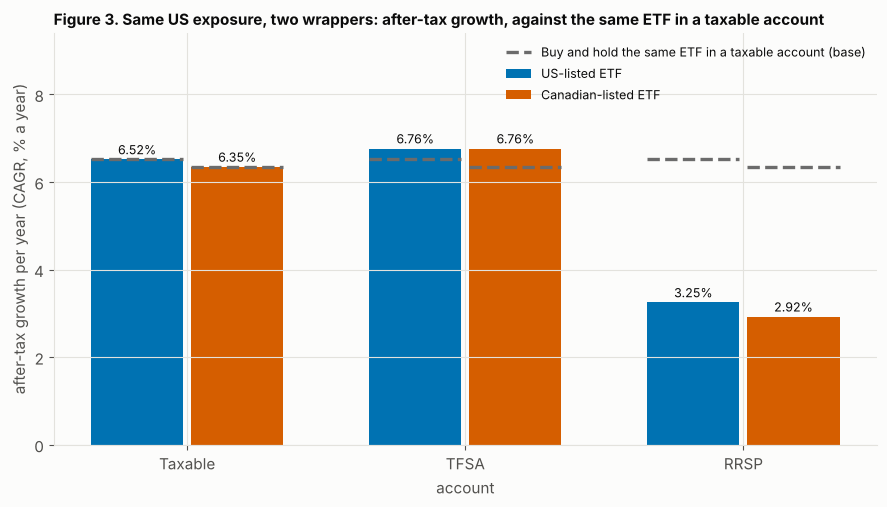

In [8]:
fig, ax = plt.subplots(figsize=(9, 5.2))
x = np.arange(3); w = 0.36
for k, n in enumerate(SPEC2):
    v = np.array([T2.loc[(n, a), "post"] for a in ACCOUNTS]) * 100
    bars = ax.bar(x + (k - .5) * w, v, w * 0.92, color=W_COL[n], label=NICE2[n])
    for b, y in zip(bars, v):
        ax.text(b.get_x() + b.get_width() / 2, y + 0.05, f"{y:.2f}%", ha="center", va="bottom", fontsize=9, color=INK)
    base = 100 * T2.loc[(n, "taxable"), "post"]
    for i in range(3):
        ax.plot([x[i] + (k - .5) * w - w * 0.46, x[i] + (k - .5) * w + w * 0.46], [base, base], color=GREY, ls="--", lw=2.4, zorder=4,
                label="Buy and hold the same ETF in a taxable account (base)" if (k, i) == (0, 0) else None)
ax.set_xticks(x, [ACC_NAME[a] for a in ACCOUNTS]); ax.set_xlabel("account"); ax.set_ylabel("after-tax growth per year (CAGR, % a year)")
ax.set_ylim(0, 9.4)
ax.set_title("Figure 3. Same US exposure, two wrappers: after-tax growth, against the same ETF in a taxable account", loc="left", fontsize=11, fontweight="bold")
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout(); display(fig); plt.close(fig)

The RRSP bars in Figure 3 include the assumed 30% tax on the whole balance at withdrawal, so the two wrappers should be compared inside one account and not across accounts. The bars show only the gap in growth. Figure 4 shows where the gap comes from, year by year, in dollars of withholding on a \$100,000 start (the amounts grow with the account). Rows are the wrapper and columns the account; orange is lost, light blue is credited back, green is exempt. The grey dashed line is the base case, the withholding the same ETF loses in a taxable account, which is zero for the US-listed ETF because the credit returns it.

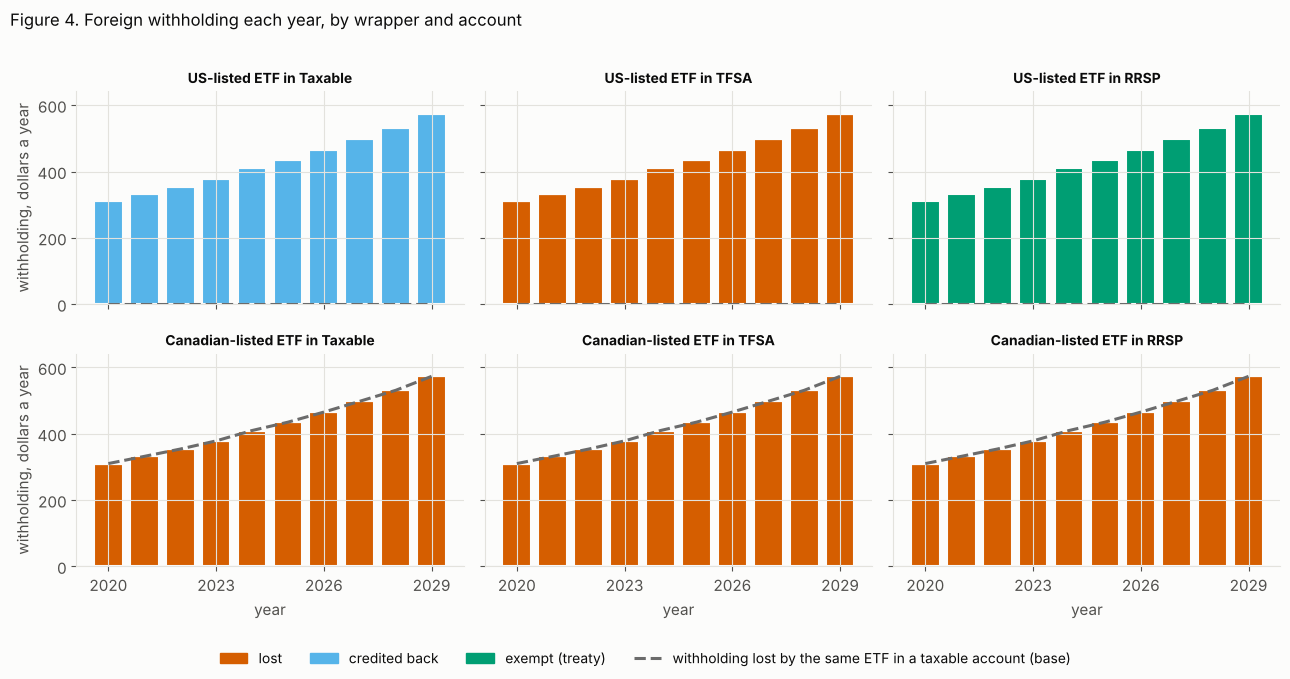

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.8), sharey=True, sharex=True)
ymax = max(max(wh[["lost", "credited", "exempt"]].sum(axis=1).max() for wh in WH2.values()), 1) * 1.12
for i, n in enumerate(SPEC2):
    base_lost = WH2[(n, "taxable")]["lost"]
    for j, a in enumerate(ACCOUNTS):
        ax = axes[i, j]; wh = WH2[(n, a)]
        bottom = np.zeros(len(wh))
        for s in ("lost", "credited", "exempt"):
            ax.bar(wh.index, wh[s], 0.8, bottom=bottom, color=STATE_COL[s], edgecolor=SURFACE, linewidth=1.5)
            bottom += wh[s].to_numpy()
        ax.plot(base_lost.index, base_lost, color=GREY, ls="--", lw=2.2, zorder=4)
        ax.set_title(f"{NICE2[n]} in {ACC_NAME[a]}", fontsize=10)
        ax.set_xticks(wh.index[::3]); ax.set_ylim(0, ymax)
        if j == 0: ax.set_ylabel("withholding, dollars a year")
        if i == 1: ax.set_xlabel("year")
fig.legend(handles=[Patch(color=STATE_COL["lost"], label="lost"), Patch(color=STATE_COL["credited"], label="credited back"),
                    Patch(color=STATE_COL["exempt"], label="exempt (treaty)"),
                    plt.Line2D([], [], color=GREY, ls="--", lw=2.2, label="withholding lost by the same ETF in a taxable account (base)")],
           loc="lower center", ncols=4, fontsize=10, frameon=False)
fig.suptitle("Figure 4. Foreign withholding each year, by wrapper and account", x=0.01, ha="left", fontsize=12)
fig.tight_layout(rect=(0, 0.06, 1, 0.97)); display(fig); plt.close(fig)

In [10]:
tf_us = T2.loc[("US_ETF", "tfsa")]; tf_ca = T2.loc[("CA_ETF", "tfsa")]
say(f'''
### What the evidence says

The wrapper mattered most where the holding was kept. The Canadian-listed ETF lost {usd(T2.loc[("CA_ETF", "taxable"), "lost"])} of withholding in all three accounts over ten years, the same {usd(T2.loc[("CA_ETF", "tfsa"), "lost"])} in each. The US-listed ETF lost it only in the TFSA, had it returned as a credit in the taxable account ({usd(T2.loc[("US_ETF", "taxable"), "credited"])}) and never paid it in the RRSP. Measured as growth a year against the same ETF in a taxable account, the US-listed ETF gained {pts(tf_us["vs_base"])} points in the TFSA and the Canadian-listed one {pts(tf_ca["vs_base"])}. Between the two wrappers the gap was {pts(gap["taxable"])} points a year in the taxable account, {pts(gap["tfsa"])} in the TFSA and {pts(gap["rrsp"])} in the RRSP. In a TFSA the two wrappers therefore tied: both lost {usd(tf_us["lost"])} and finished at {100 * tf_us["post"]:.2f}% a year. In a taxable account the US-listed ETF was ahead by the amount of the credit, and in an RRSP it was clearly ahead because it paid no withholding at all. The fees and the cost of converting currency on the two products are not modelled and would adjust these gaps.
''')
assert abs(gap["tfsa"]) < 1e-6 and gap["taxable"] > 0 and gap["rrsp"] > gap["taxable"]


### What the evidence says

The wrapper mattered most where the holding was kept. The Canadian-listed ETF lost \$4,286 of withholding in all three accounts over ten years, the same \$4,286 in each. The US-listed ETF lost it only in the TFSA, had it returned as a credit in the taxable account (\$4,286) and never paid it in the RRSP. Measured as growth a year against the same ETF in a taxable account, the US-listed ETF gained 0.25 points in the TFSA and the Canadian-listed one 0.42. Between the two wrappers the gap was 0.17 points a year in the taxable account, 0.00 in the TFSA and 0.33 in the RRSP. In a TFSA the two wrappers therefore tied: both lost \$4,286 and finished at 6.76% a year. In a taxable account the US-listed ETF was ahead by the amount of the credit, and in an RRSP it was clearly ahead because it paid no withholding at all. The fees and the cost of converting currency on the two products are not modelled and would adjust these gaps.


## 3. Currency and the cost base

Sections 1 and 2 held the exchange rate flat, and this section moves it, because withholding is only half of what makes a foreign holding different. Tax is computed in Canadian dollars. The adjusted cost base (ACB) of a US share is what you paid converted at the exchange rate on the day you bought, and the proceeds are converted at the rate on the day you sold, so a gain in US dollars can be a loss in Canadian dollars.

The test is to buy a US stock on 2020-01-01 with USDCAD at 1.40 and sell it on 2021-01-01 (the screen switches to a Canadian stock for 2021). There are no dividends, so the currency is the only thing in play. In **Case A** the US-dollar price rises 10% and USDCAD falls 15% (1.40 to 1.19). In **Case B**, the reverse, the US-dollar price falls 5% and USDCAD rises 15% (1.40 to 1.61).

**The base case is the same stock with the exchange rate held at its buy-day value**, which is simply the US-dollar price: it shows what the holding did before the currency is counted. It is the grey dashed line in Figure 5 and the rows marked "buy and hold, currency ignored" in Table 3, which are also what the tax stage computes when no exchange-rate series is loaded.

In [11]:
rows = []
for k, (usd_move, fx_move) in CASES.items():
    for label, key in (("Buy and hold, currency ignored (US-dollar view; base)", "usd"), ("Currency counted (Canadian-dollar view; what the CRA taxes)", "cad")):
        c3 = C3[(k, key)]
        rows.append({"case": k, "USD price": f"{usd_move:+.0%}", "USDCAD": f"{fx_move:+.0%}", "view": label,
                     "realized gain ($)": c3["gain"], "realized loss ($)": c3["loss"], "net gain or loss ($)": c3["net"],
                     "capital gains tax ($)": c3["tax"], "net minus base ($)": c3["net"] - C3[(k, "usd")]["net"],
                     "tax minus base ($)": c3["tax"] - C3[(k, "usd")]["tax"]})
g = pd.DataFrame(rows).set_index(["case", "USD price", "USDCAD", "view"])
print("Table 3. The taxable result of each case, with and without the currency, on $100,000")
display(g.style.format("{:,.0f}"))
a_cad = RES3["A"][2]["cad"].loc[2021]; b_cad = RES3["B"][2]["cad"].loc[2021]
assert abs(a_cad["realized_losses"] - CAP * (1.10 * 0.85 - 1)) < 1e-6      # exact: 1.10 x 0.85 - 1 = -6.5%
assert abs(b_cad["realized_gains"] - CAP * (0.95 * 1.15 - 1)) < 1e-6       # exact: 0.95 x 1.15 - 1 = +9.25%
print(f"Case A: the US-dollar gain is +10%, the Canadian-dollar result is 1.10 x 0.85 - 1 = {1.10 * 0.85 - 1:+.2%}, "
      f"a loss of ${-a_cad['realized_losses']:,.0f} on $100,000, and no tax.")
print(f"Case B: the US-dollar result is -5%, the Canadian-dollar result is 0.95 x 1.15 - 1 = {0.95 * 1.15 - 1:+.2%}, "
      f"a gain of ${b_cad['realized_gains']:,.0f}, taxed: ${b_cad['tax_capital_gains']:,.0f}.")

Table 3. The taxable result of each case, with and without the currency, on $100,000


Case A: the US-dollar gain is +10%, the Canadian-dollar result is 1.10 x 0.85 - 1 = -6.50%, a loss of $6,500 on $100,000, and no tax.
Case B: the US-dollar result is -5%, the Canadian-dollar result is 0.95 x 1.15 - 1 = +9.25%, a gain of $9,250, taxed: $1,411.


Figure 5 has two rows. The top row shows, for each case, the price in US dollars (the base case, grey dashed), the same price converted to Canadian dollars (vermillion) and the cost base (black line at 100). The shaded gap between the Canadian-dollar price and the cost base is what the CRA taxes (green) or lets you claim as a loss (red). The bottom row shows USDCAD, with the buy-day rate of 1.40 as the base.

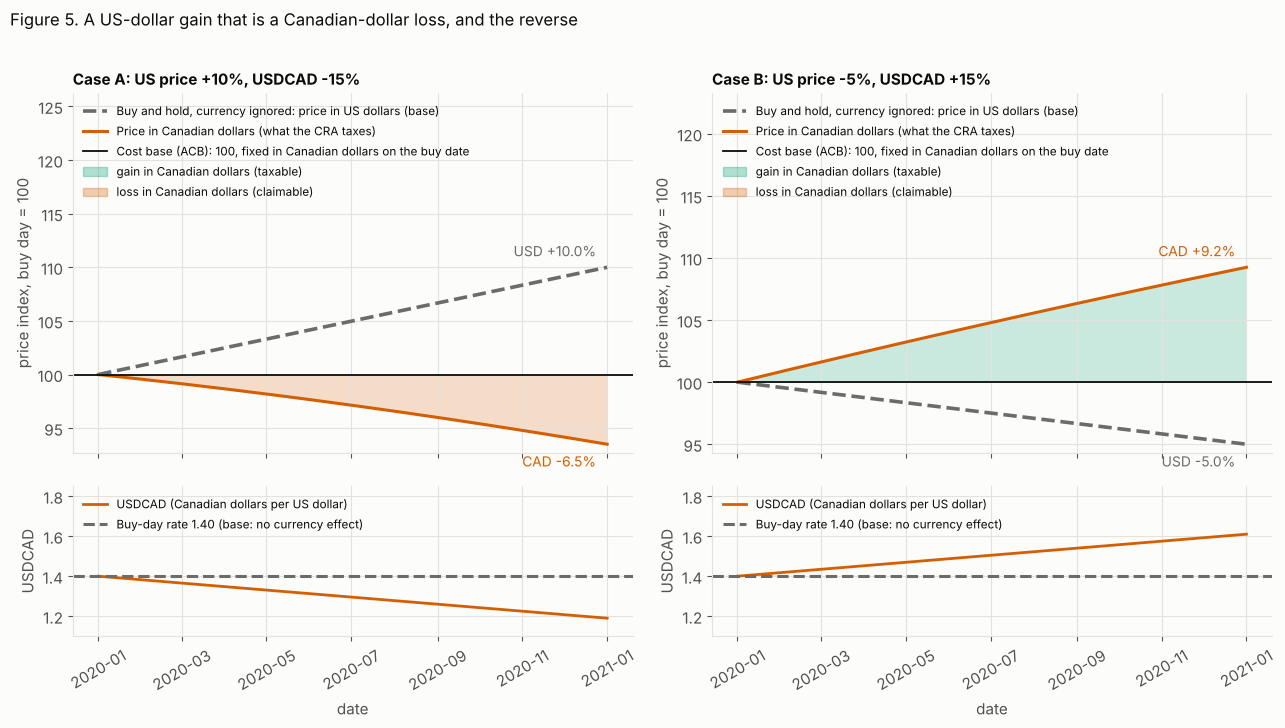

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7.4), sharex=True, gridspec_kw=dict(height_ratios=[2.4, 1]))
for j, (k, (usd_move, fx_move)) in enumerate(CASES.items()):
    usd_px, fx, out = RES3[k]
    sell = pd.Timestamp("2021-01-01"); keep = usd_px.index <= sell
    usd_i = 100 * usd_px[keep]; cad_i = 100 * usd_px[keep] * fx[keep] / FX0
    ax = axes[0, j]
    ax.plot(usd_i.index, usd_i, color=GREY, lw=2.6, ls="--", label="Buy and hold, currency ignored: price in US dollars (base)")
    ax.plot(cad_i.index, cad_i, color="#D55E00", lw=2.2, label="Price in Canadian dollars (what the CRA taxes)")
    ax.axhline(100, color=INK, lw=1.3, label="Cost base (ACB): 100, fixed in Canadian dollars on the buy date")
    ax.fill_between(cad_i.index, 100, cad_i, where=cad_i >= 100, color="#009E73", alpha=0.2, lw=0)
    ax.fill_between(cad_i.index, 100, cad_i, where=cad_i < 100, color="#D55E00", alpha=0.2, lw=0)
    ax.annotate(f"USD {usd_i.iloc[-1] - 100:+.1f}%", (sell, usd_i.iloc[-1]), xytext=(-8, 8 if usd_i.iloc[-1] >= cad_i.iloc[-1] else -16),
                textcoords="offset points", ha="right", fontsize=10, color=GREY)
    ax.annotate(f"CAD {cad_i.iloc[-1] - 100:+.1f}%", (sell, cad_i.iloc[-1]), xytext=(-8, -16 if usd_i.iloc[-1] >= cad_i.iloc[-1] else 8),
                textcoords="offset points", ha="right", fontsize=10, color="#D55E00")
    lo_, hi_ = ax.get_ylim(); ax.set_ylim(lo_, hi_ + (hi_ - lo_) * 0.85)           # headroom for the legend
    h, l = ax.get_legend_handles_labels()
    h += [Patch(color="#009E73", alpha=0.3, label="gain in Canadian dollars (taxable)"), Patch(color="#D55E00", alpha=0.3, label="loss in Canadian dollars (claimable)")]
    ax.legend(handles=h, loc="upper left", fontsize=8.5)
    ax.set_title(f"Case {k}: US price {usd_move:+.0%}, USDCAD {fx_move:+.0%}", loc="left", fontsize=11, fontweight="bold"); ax.set_ylabel("price index, buy day = 100")
    axf = axes[1, j]
    axf.plot(fx[keep].index, fx[keep], color="#D55E00", lw=2, label="USDCAD (Canadian dollars per US dollar)")
    axf.axhline(FX0, color=GREY, ls="--", lw=2.2, label="Buy-day rate 1.40 (base: no currency effect)")
    axf.set_ylabel("USDCAD"); axf.set_xlabel("date"); axf.set_ylim(1.1, 1.85); axf.tick_params(axis="x", rotation=30)
    axf.legend(loc="upper left", fontsize=8.5)
fig.suptitle("Figure 5. A US-dollar gain that is a Canadian-dollar loss, and the reverse", x=0.01, ha="left", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.97)); display(fig); plt.close(fig)

### With no exchange-rate series

If no exchange-rate series is loaded, the tax stage cannot convert, taxes the US-dollar numbers as if they were Canadian dollars, and says so. The base-case rows of Table 3 are what that produces. The warning appeared in both cases, and the Canadian-dollar runs, which had the series, did not carry it.

In [13]:
for k in CASES:
    w = RES3[k][2]["usd"].attrs["warnings"]
    print(f"Case {k}, no FX series -> warning: {FX_WARNING}")
    assert FX_WARNING in w and FX_WARNING not in RES3[k][2]["cad"].attrs["warnings"]

Case A, no FX series -> warning: foreign gains taxed in portfolio currency; load an FX series for CAD basis
Case B, no FX series -> warning: foreign gains taxed in portfolio currency; load an FX series for CAD basis


In [14]:
say(f'''
### What the evidence says

The currency decided both the size and the sign of the taxable result. In Case A the base case showed a gain of {usd(C3[("A", "usd")]["gain"])} and a tax of {usd(C3[("A", "usd")]["tax"])}, but in Canadian dollars the result was 1.10 x 0.85 - 1 = {1.10 * 0.85 - 1:+.2%}, a loss of {usd(-C3[("A", "cad")]["loss"])} and no tax, so ignoring the currency overstated the taxable result by {usd(C3[("A", "usd")]["net"] - C3[("A", "cad")]["net"])}. In Case B the base case showed a loss of {usd(-C3[("B", "usd")]["loss"])} and no tax, but the Canadian-dollar result was 0.95 x 1.15 - 1 = {0.95 * 1.15 - 1:+.2%}, a gain of {usd(C3[("B", "cad")]["gain"])} taxed {usd(C3[("B", "cad")]["tax"])}, so ignoring the currency understated the taxable result by {usd(C3[("B", "cad")]["net"] - C3[("B", "usd")]["net"])} and hid a tax bill of {usd(C3[("B", "cad")]["tax"])}. In each case the currency moved the taxable result by more than the US-dollar price did ({usd(abs(C3[("A", "cad")]["net"] - C3[("A", "usd")]["net"]))} against {usd(abs(C3[("A", "usd")]["net"]))} in Case A, {usd(abs(C3[("B", "cad")]["net"] - C3[("B", "usd")]["net"]))} against {usd(abs(C3[("B", "usd")]["net"]))} in Case B), and it reversed the sign. To avoid the error the series must be USDCAD (Canadian dollars per US dollar, as a `MacroSeries` column `fx`); it converts gains and the dividends of names whose `currency` is USD.
''')
assert all(abs(C3[(k, "cad")]["net"] - C3[(k, "usd")]["net"]) > abs(C3[(k, "usd")]["net"]) for k in "AB")
assert C3[("A", "cad")]["net"] < 0 < C3[("A", "usd")]["net"] and C3[("B", "cad")]["net"] > 0 > C3[("B", "usd")]["net"]


### What the evidence says

The currency decided both the size and the sign of the taxable result. In Case A the base case showed a gain of \$10,000 and a tax of \$1,525, but in Canadian dollars the result was 1.10 x 0.85 - 1 = -6.50%, a loss of \$6,500 and no tax, so ignoring the currency overstated the taxable result by \$16,500. In Case B the base case showed a loss of \$5,000 and no tax, but the Canadian-dollar result was 0.95 x 1.15 - 1 = +9.25%, a gain of \$9,250 taxed \$1,411, so ignoring the currency understated the taxable result by \$14,250 and hid a tax bill of \$1,411. In each case the currency moved the taxable result by more than the US-dollar price did (\$16,500 against \$10,000 in Case A, \$14,250 against \$5,000 in Case B), and it reversed the sign. To avoid the error the series must be USDCAD (Canadian dollars per US dollar, as a `MacroSeries` column `fx`); it converts gains and the dividends of names whose `currency` is USD.


## 4. Real data: the S&P 500 sample

The hand-made markets isolated each effect. The question now is whether the same effects show up on real prices, and how large they are next to a base case that exists in the data. **Here the base case is the S&P 500 index bought and held in the same account, taxed the same way**, the grey dashed line in Figure 6 and the first row of each account in Table 4.

The bundled sample has 20 large US companies (1990-2022, prices only, in US dollars). As in `accounts_and_foreign.ipynb`, an assumed 2% yield is added so that dividends exist for the tax stage to withhold on; the 2% is an assumption and not data. Every name is a US stock, so the foreign treatment is the "US stock, direct" row of Section 1. The portfolio is a five-stock 12-month momentum screen (`momentum_12_1`). No exchange-rate series is loaded, so gains are taxed in US dollars as if they were Canadian, which the comparison says in its notes.

In [15]:
import re
print(sp_rep.data_card.line()); print(sp_rep.data_card.foreign_line())
print([n for n in sp_rep.notes if n.startswith('CAD-basis')])
cols = ["CAGR", "AfterTaxCAGR", "TaxDrag/yr", "AfterTaxExcess/yr", "WHLost/yr", "WHCredited/yr", "WHExempt/yr", "TaxPaid$"]
t4 = sp_rep.table.copy()
t4["holding"] = np.where(t4["kind"] == "index", "Buy and hold the index (base)", "Momentum screen")
t4["account"] = t4["account"].map(ACC_NAME)
t4 = t4.set_index(["account", "holding"])[cols]
t4 = t4.loc[[(ACC_NAME[a], h) for a in ACCOUNTS for h in ("Buy and hold the index (base)", "Momentum screen")]]
t4.columns = ["Growth a year before tax", "Growth a year after tax", "Tax drag", "After-tax growth minus base", "Withholding lost a year", "Credited back a year", "Exempt a year", "Tax paid ($)"]
print("Table 4. The momentum screen and its base case in each account")
t4.style.format({c: "{:.2%}" for c in t4.columns[:-1]} | {"Tax paid ($)": "{:,.0f}"}, na_rep="-")

Data: sp500_bundled+2%div, 1990-01-02..2022-12-28, 20 names, benchmark SP500 (approx_total_return: price index + assumed 2.0%/yr dividends), PIT n/a, delisted no, survivorship +7.9%/yr
foreign: 100% of names (US 100%), currencies USD; withholding: taxable creditable (FTC), tfsa lost, rrsp exempt (US-listed); Canadian ETF on foreign stocks: lost in every account
foreign: 100% of names (US 100%), currencies USD; withholding: taxable creditable (FTC), tfsa lost, rrsp exempt (US-listed); Canadian ETF on foreign stocks: lost in every account
['CAD-basis warning: foreign gains taxed in portfolio currency; load an FX series for CAD basis']
Table 4. The momentum screen and its base case in each account


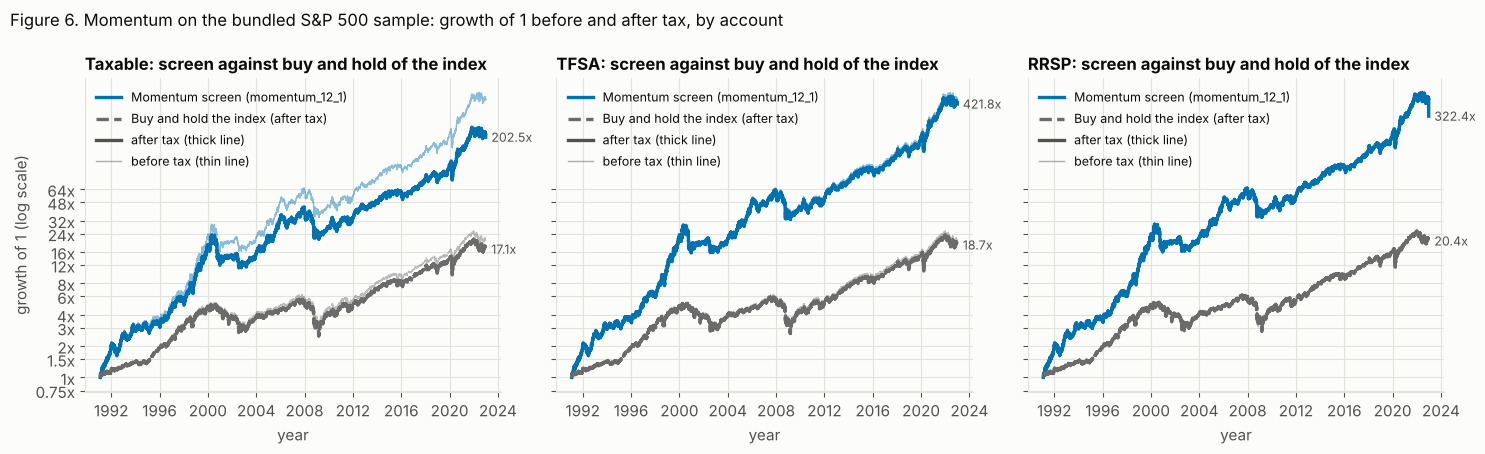

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, a in zip(axes, ACCOUNTS):
    r = sp_rep.reports[a]
    tp.after_tax_curves({"Momentum screen (momentum_12_1)": r.results["momentum_12_1"], "Buy and hold the index (after tax)": tp.index_result(r)},
                        ax=ax, title=f"{ACC_NAME[a]}: screen against buy and hold of the index")
    ax.set_xlabel("year")
for ax in axes[1:]:
    ax.set_ylabel("")
fig.suptitle("Figure 6. Momentum on the bundled S&P 500 sample: growth of 1 before and after tax, by account", x=0.01, ha="left", fontsize=12)
fig.tight_layout(); display(fig); plt.close(fig)

In [17]:
P, X = "portfolio", "index"
say(f'''
### What the evidence says

The withholding showed up on real prices as the matrix predicted. On the "US stock, direct" rule the screen lost {pts(SPT.loc[(P, "tfsa"), "WHLost/yr"])} points a year to withholding in the TFSA, had {pts(SPT.loc[(P, "taxable"), "WHCredited/yr"])} points a year credited back in the taxable account and had {pts(SPT.loc[(P, "rrsp"), "WHExempt/yr"])} points a year exempt in the RRSP, the same {pts(SPT.loc[(X, "tfsa"), "WHLost/yr"])} points that the base case lost in the TFSA, so the withholding cost the screen and the index the same. The tax drag was {pts(SPT.loc[(P, "taxable"), "TaxDrag/yr"])} points a year for the screen in the taxable account against {pts(SPT.loc[(X, "taxable"), "TaxDrag/yr"])} for the base case, because the screen sells and the index does not; in the TFSA it was {pts(SPT.loc[(P, "tfsa"), "TaxDrag/yr"])} against {pts(SPT.loc[(X, "tfsa"), "TaxDrag/yr"])}, which is withholding alone. The screen finished {pts(SPT.loc[(P, "taxable"), "AfterTaxExcess/yr"])}, {pts(SPT.loc[(P, "tfsa"), "AfterTaxExcess/yr"])} and {pts(SPT.loc[(P, "rrsp"), "AfterTaxExcess/yr"])} points a year ahead of buy and hold of the index in the taxable account, TFSA and RRSP. That excess is mostly the sample's survivorship bias (the data card reports survivorship of {re.search(r"survivorship ([+-][0-9.]+%/yr)", sp_rep.data_card.line()).group(1)}) and says nothing about momentum; what the comparison does show is that the account moved it by {pts(SPT.xs(P, level="kind")["AfterTaxExcess/yr"].max() - SPT.xs(P, level="kind")["AfterTaxExcess/yr"].min())} points.
''')
assert SPT.loc[(P, "tfsa"), "WHLost/yr"] > 0 and SPT.loc[(P, "taxable"), "WHLost/yr"] == 0


### What the evidence says

The withholding showed up on real prices as the matrix predicted. On the "US stock, direct" rule the screen lost 0.30 points a year to withholding in the TFSA, had 0.30 points a year credited back in the taxable account and had 0.30 points a year exempt in the RRSP, the same 0.30 points that the base case lost in the TFSA, so the withholding cost the screen and the index the same. The tax drag was 3.08 points a year for the screen in the taxable account against 0.64 for the base case, because the screen sells and the index does not; in the TFSA it was 0.33 against 0.31, which is withholding alone. The screen finished 8.84, 11.26 and 11.15 points a year ahead of buy and hold of the index in the taxable account, TFSA and RRSP. That excess is mostly the sample's survivorship bias (the data card reports survivorship of +7.9%/yr) and says nothing about momentum; what the comparison does show is that the account moved it by 2.42 points.


## 5. The findings together and what they leave out

The four sections isolated one effect each, and the question is what they add up to for a Canadian who holds foreign stocks or funds. The numbers below repeat those of the sections; none is new.

In [18]:
say(f'''
### What the evidence says

Withholding is not one cost: the same {rate:.0%} was lost, credited or exempt depending on the account and the wrapper, and where a holding lived mattered as much as which holding it was. The Canadian-listed ETF on US stocks lost it in every account ({usd(T2.loc[("CA_ETF", "taxable"), "lost"])} over ten years per {usd(CAP)}), the US-listed ETF lost it only in the TFSA ({usd(T2.loc[("US_ETF", "tfsa"), "lost"])}), and a US stock held directly lost it only in the TFSA as well ({usd(I1.loc[(us, "tfsa"), "lost"])} in one year). The gap between the wrappers was {pts(gap["taxable"])}, {pts(gap["tfsa"])} and {pts(gap["rrsp"])} points a year in the taxable account, TFSA and RRSP. The currency changed the taxable result by {usd(abs(C3[("A", "cad")]["net"] - C3[("A", "usd")]["net"]))} and {usd(abs(C3[("B", "cad")]["net"] - C3[("B", "usd")]["net"]))} in the two cases, in each of them reversing its sign. In dollars the currency effect was the larger of the two: it moved the taxable result by {usd(abs(C3[("A", "cad")]["net"] - C3[("A", "usd")]["net"]))} and {usd(abs(C3[("B", "cad")]["net"] - C3[("B", "usd")]["net"]))} in the two cases, reversing its sign each time, where the withholding was {usd(I1.loc[(us, "tfsa"), "lost"])} a year on the same {usd(CAP)}. The two do not compare directly, since the withholding repeats every year and the currency effect depends on how far USDCAD moves between the purchase and the sale. Where the choice was open, the runs favoured the RRSP for a US stock held directly and the US-listed ETF over the Canadian-listed one, in each case by the withholding the alternative lost, and the TFSA was neutral between the two wrappers. A foreign gain should not be read until an exchange-rate series is loaded.
''')


### What the evidence says

Withholding is not one cost: the same 15% was lost, credited or exempt depending on the account and the wrapper, and where a holding lived mattered as much as which holding it was. The Canadian-listed ETF on US stocks lost it in every account (\$4,286 over ten years per \$100,000), the US-listed ETF lost it only in the TFSA (\$4,286), and a US stock held directly lost it only in the TFSA as well (\$600 in one year). The gap between the wrappers was 0.17, 0.00 and 0.33 points a year in the taxable account, TFSA and RRSP. The currency changed the taxable result by \$16,500 and \$14,250 in the two cases, in each of them reversing its sign. In dollars the currency effect was the larger of the two: it moved the taxable result by \$16,500 and \$14,250 in the two cases, reversing its sign each time, where the withholding was \$600 a year on the same \$100,000. The two do not compare directly, since the withholding repeats every year and the currency effect depends on how far USDCAD moves between the purchase and the sale. Where the choice was open, the runs favoured the RRSP for a US stock held directly and the US-listed ETF over the Canadian-listed one, in each case by the withholding the alternative lost, and the TFSA was neutral between the two wrappers. A foreign gain should not be read until an exchange-rate series is loaded.


### With your own data

Load a total-return series for the names you hold (or a screen-ready `fundamentals.csv` with dividends) and add a `securities.csv` next to it with one row per ticker and the columns `ticker, domicile, wrapper, currency, underlying_domicile` (blank cells get the defaults: Canada, CAD, `stock`). Set `wrapper` to `etf_ca` and `underlying_domicile` to `US` for a Canadian-listed US ETF, and `etf_us` for a US-listed one. Then the data card shows `foreign: ...` and the matrix from Section 1 is applied to your names and not to an assumed 2% yield. For USD names, load a USDCAD series as a macro `fx` column and pass it as `TaxConfig(macro=...)`; otherwise Section 3's warning applies.

### What this ignores

* **Only USD is converted.** The tax stage reads one FX series, `fx_currency="USD"`. Names in other currencies (GBP, EUR) are not converted; their withholding rate is by country, but their gains are not put on a CAD basis.
* **Fund NAV already net of withholding.** If the total-return series you load for an ETF is the fund's own NAV, the fund's internal withholding is already in it, and the tax stage then takes it a second time. Use a gross-of-withholding series, or accept a small double count.
* **Forms and special rules:** T1135 (foreign property over \$100,000 CAD held outside registered accounts), estate-tax exposure on US securities above the US exemption, PFIC treatment of foreign funds, and the foreign tax credit limits beyond the simple approximation (the credit is capped at the Canadian tax on that income).
* **Trading costs of converting currency**, fund fees, and the interest on cash balances in USD.
* **Contribution room**, the RRSP deduction refund, and AMT, as in the accounts notebook.
* Taxes are Alberta 2025 for a \$90,000 salary; the hand-made markets are made up and flat on purpose. The numbers show the mechanics. They are not a forecast and not tax advice.